In [ ]:
from pathlib import Path
import sys

for _parent in (Path.cwd(), *Path.cwd().parents):
    if (_parent / "src" / "regression_module.py").exists():
        sys.path.insert(0, str(_parent / "src"))
        break


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from regression_module import compute_cost, compute_gradient, run_gradient_descent, z_score_normalization
np.set_printoptions(precision=2)

In [2]:
x = np.arange(20)
y = 1 + x ** 2
X = x.reshape(-1, 1) # column matrix

model_w, model_b = run_gradient_descent(X, y, alpha=1e-2, iterations=1000)

w, b found by gradient descent: [18.7], -52.08341025448667


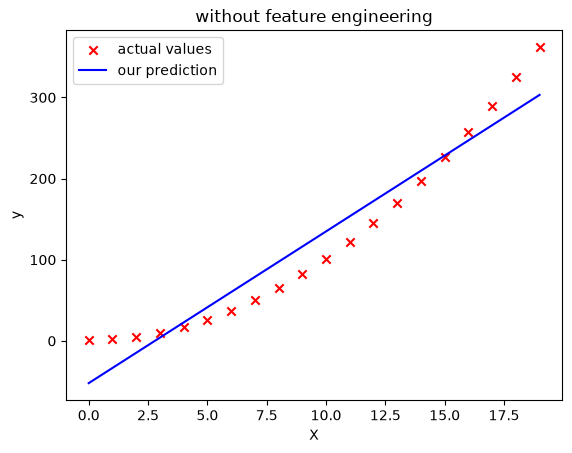

In [3]:
plt.scatter(x, y, marker='x', c='r', label='actual values')
plt.title('without feature engineering')
plt.plot(x, X@model_w + model_b, c='b', label='our prediction')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [4]:
x = np.arange(20)
y = 1 + x ** 2
X = x ** 2 # -> added engineered feature 
X = X.reshape(-1,1) # column matrix

model_w, model_b = run_gradient_descent(X, y, alpha=1e-5, iterations=10000)

w, b found by gradient descent: [1.], 0.04896443659681638


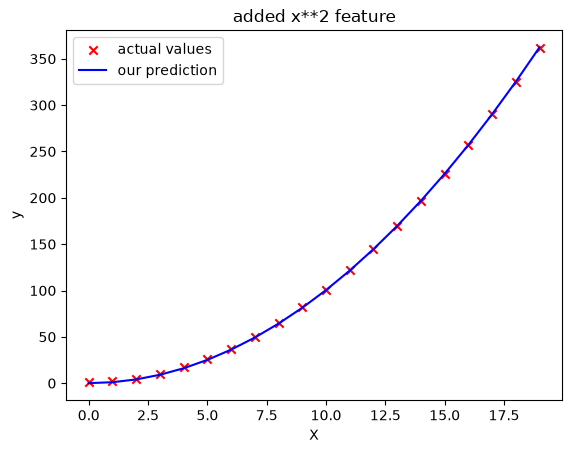

In [5]:
# now plot
plt.scatter(x, y, marker='x', c='r', label='actual values')
plt.title('added x**2 feature')
plt.plot(x, X@model_w + model_b, c='b', label='our prediction')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [6]:
# so above we new that x^2 should be added but what if we are not so sure
# we can try a number of potential polynomial features to be added it will automatically adjust
# the parameters so that best one will have more impact on our prediction
# but adding too much features will have a side effect also as well

In [7]:
x = np.arange(20)
y = x ** 2

# engineer features

X = np.c_[x, x**2, x**3] # <-- added engineered features

model_w, model_b = run_gradient_descent(X, y, iterations=10000, alpha=1e-7)

w, b found by gradient descent: [0.08 0.54 0.03], 0.01056185052956357


In [8]:
# as we can above see x^2 has more impact on overall predict because it has comparatively large value

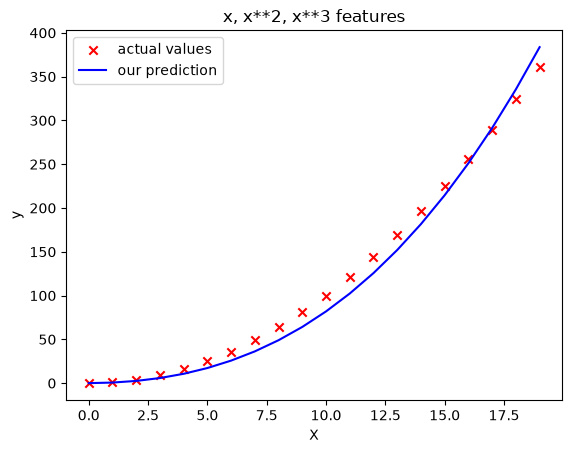

In [9]:
plt.scatter(x, y, marker='x', c='r', label='actual values')
plt.title('x, x**2, x**3 features')
plt.plot(x, X@model_w + model_b, c='b', label='our prediction')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [10]:
# alright so here we are as we can see above our implied prediction
#Gradient descent has emphasized the data that is the best fit to the  𝑥2
#data by increasing the  𝑤1
#term relative to the others. If you were to run for a very long time, it would continue to reduce the impact of the other terms.

In [11]:
# feature scaling
# now we can implement our idea of feature scaling in this context of polynomial regression
# as in above x, x**2, and x**3 has different scales we will first rescale these features to comparable ranges
# and then again find our model function

In [12]:
x = np.arange(20)
y = x ** 2
X = np.c_[x, x**2, x**3]

print(f"Peak to peak range by column in raw:  X:{np.ptp(X, axis=0)}")
# now let's perform  feature scaling

X = z_score_normalization(X)

print(f"Peak to peak range by column in normalized:  X:{np.ptp(X, axis=0)}")


Peak to peak range by column in raw:  X:[  19  361 6859]
Peak to peak range by column in normalized:  X:[3.3  3.18 3.28]


In [13]:
# alright as we can see from above result the scaled features are  now in comparable ranges
# now let's again find our model function

In [14]:
x = np.arange(20)
y = x**2

X = np.c_[x, x**2, x**3] # engineered features
X = z_score_normalization(X) # rescaled features

model_w, model_b = run_gradient_descent(X, y, alpha=0.1, iterations=100000)

w, b found by gradient descent: [5.27e-05 1.13e+02 8.43e-05], 123.49999999999994


In [15]:
# as seen above x**2 (w1) has huge impact on our model predict comparision to other w0 and w2

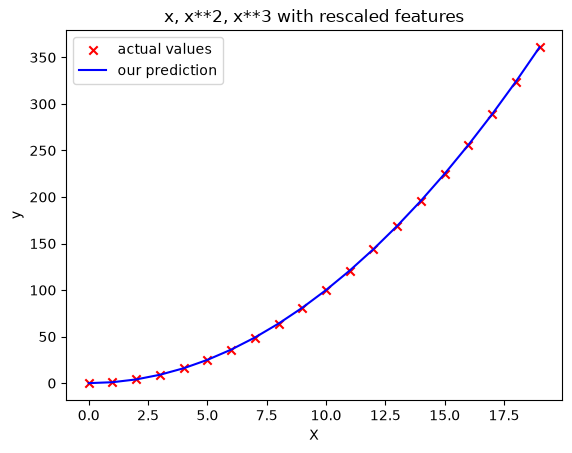

In [16]:
plt.scatter(x, y, marker='x', c='r', label='actual values')
plt.title('x, x**2, x**3 with rescaled features')
plt.plot(x, X@model_w + model_b, c='b', label='our prediction')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [17]:
# ya!

In [18]:
# with feature engineering we can model quite complex functions for example

In [19]:
x = np.arange(20)
y = np.cos(x/2)

X = np.c_[x, x**2, x**3, x**4, x**5, x**6, x**7, x**8, x**9, x**10, x**11, x**12, x**13]

X = z_score_normalization(X)

model_w, model_b = run_gradient_descent(X, y, iterations=1000000, alpha=0.1)

w, b found by gradient descent: [ -1.34 -10.    24.78   5.96 -12.49 -16.26  -9.51   0.59   8.7   11.94
   9.27   0.79 -12.82], -0.0072871948558394


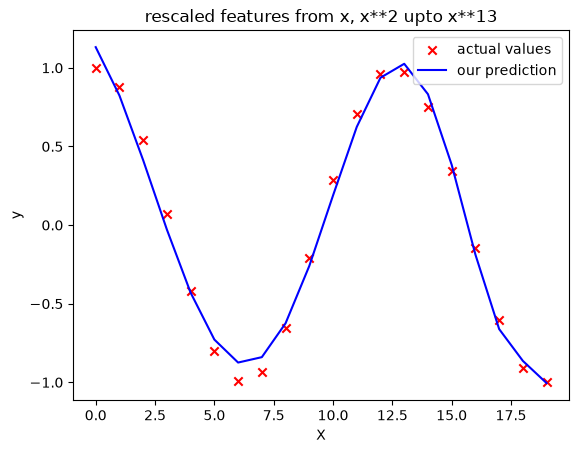

In [20]:
plt.scatter(x, y, marker='x', c='r', label='actual values')
plt.title('rescaled features from x, x**2 upto x**13')
plt.plot(x, X@model_w + model_b, c='b', label='our prediction')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()